<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Spam-message-detection/blob/main/Spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


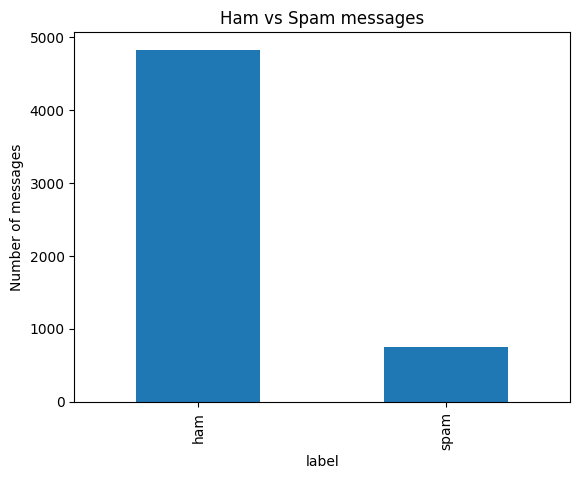

Naive Bayes accuracy: 0.97
Logistic Regression accuracy: 0.968
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



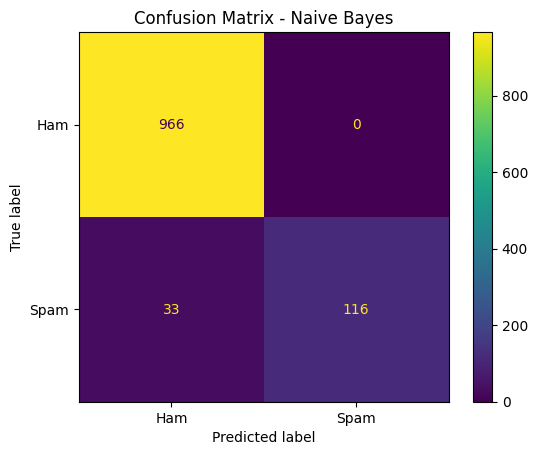

Top spam words: ['claim', 'prize', '150p', 'www', 'uk', 'tone', '18', 'guaranteed', '1000', 'cs']
'Congratulations! You won a free prize. Call now to claim' -> SPAM
'Hey, are we meeting for lunch tomorrow?' -> HAM


In [1]:
# Spam Message Detection using NLP
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load the SMS dataset (ham = normal message, spam = unwanted message)
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_table(url, header=None, names=["label", "message"])
print("Shape:", df.shape)
print(df["label"].value_counts())
print(df.head())

df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

# 2. Graph: how many ham vs spam
df["label"].value_counts().plot(kind="bar", title="Ham vs Spam messages")
plt.ylabel("Number of messages")
plt.show()

# 3. Split
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["label_num"], test_size=0.2, random_state=42,
    stratify=df["label_num"]
)

# 4. Turn text into numbers (TF-IDF gives more weight to important words)
vectorizer = TfidfVectorizer(stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train two models
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)

nb_pred = nb.predict(X_test_vec)
lr_pred = lr.predict(X_test_vec)
print("Naive Bayes accuracy:", round(accuracy_score(y_test, nb_pred), 3))
print("Logistic Regression accuracy:", round(accuracy_score(y_test, lr_pred), 3))

# 6. Detailed report for Naive Bayes
print(classification_report(y_test, nb_pred, target_names=["Ham", "Spam"]))

# 7. Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, nb_pred),
                       display_labels=["Ham", "Spam"]).plot()
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

# 8. Words that most strongly signal spam
words = vectorizer.get_feature_names_out()
spam_strength = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top = spam_strength.argsort()[-10:][::-1]
print("Top spam words:", [words[i] for i in top])

# 9. Try your own messages
tests = [
    "Congratulations! You won a free prize. Call now to claim",
    "Hey, are we meeting for lunch tomorrow?"
]
for text, pred in zip(tests, nb.predict(vectorizer.transform(tests))):
    print(f"'{text}' -> {'SPAM' if pred == 1 else 'HAM'}")